# Laboratorio 14. Sensibilidad, especificidad y ROC

Simulo sanos (clase 0) y enfermos (clase 1). Un valor mayor o igual al umbral se clasifica como positivo.

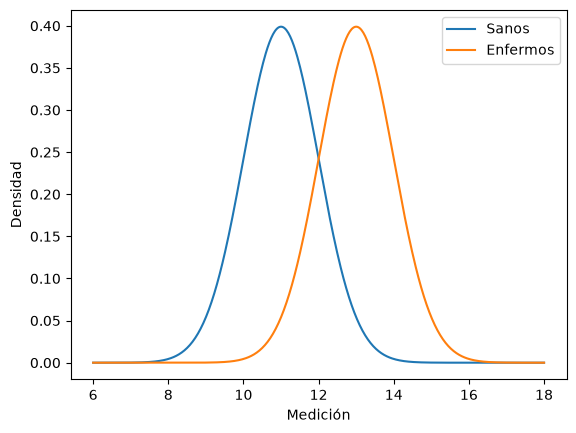

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import roc_curve, roc_auc_score

rng = np.random.default_rng(42)
sanos = rng.normal(11, 1, 1000)
enfermos = rng.normal(13, 1, 1000)
x = np.linspace(6, 18, 500)
plt.plot(x, norm.pdf(x, 11, 1), label='Sanos')
plt.plot(x, norm.pdf(x, 13, 1), label='Enfermos')
plt.xlabel('Medición')
plt.ylabel('Densidad')
plt.legend()
plt.show()

## 1. Un umbral

Sensibilidad: $VP/(VP+FN)$, fracción de enfermos detectados. Especificidad: $VN/(VN+FP)$, fracción de sanos clasificados correctamente.

,umbral,VN,FP,VP,FN,especificidad,sensibilidad
0,10,171,829,999,1,0.171,0.999
1,12,859,141,811,189,0.859,0.811
2,14,999,1,140,860,0.999,0.140


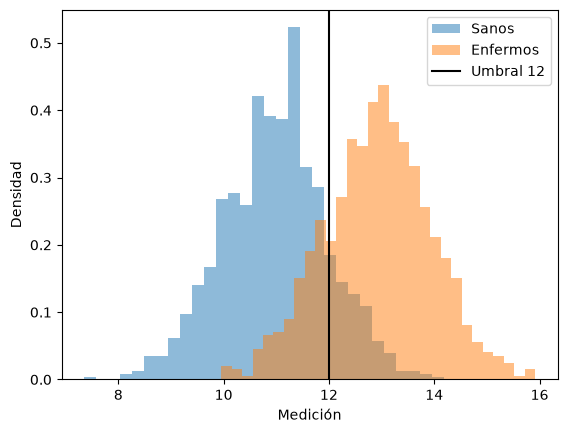

In [2]:
def metricas_umbral(sanos, enfermos, umbral):
    # Clasificamos positivos con >= y negativos con <.
    VN = np.sum(sanos < umbral)
    FP = np.sum(sanos >= umbral)
    VP = np.sum(enfermos >= umbral)
    FN = np.sum(enfermos < umbral)
    return {'umbral': umbral, 'VN': VN, 'FP': FP, 'VP': VP, 'FN': FN,
            'especificidad': VN / len(sanos), 'sensibilidad': VP / len(enfermos)}

display(pd.DataFrame([metricas_umbral(sanos, enfermos, b) for b in [10, 12, 14]]))
plt.hist(sanos, bins=30, density=True, alpha=.5, label='Sanos')
plt.hist(enfermos, bins=30, density=True, alpha=.5, label='Enfermos')
plt.axvline(12, color='black', label='Umbral 12')
plt.xlabel('Medición')
plt.ylabel('Densidad')
plt.legend()
plt.show()

Bajar el umbral aumenta la sensibilidad y los falsos positivos; subirlo tiene el efecto contrario. Con distribuciones superpuestas no se pueden maximizar ambas tasas a la vez.

,umbral,VN,FP,VP,FN,especificidad,sensibilidad,FPR,Youden
Prioridad sensibilidad,9.951952,153.0,847.0,1000.0,0.0,0.153,1.000,0.847,0.153
Youden,11.873874,833.0,167.0,841.0,159.0,0.833,0.841,0.167,0.674


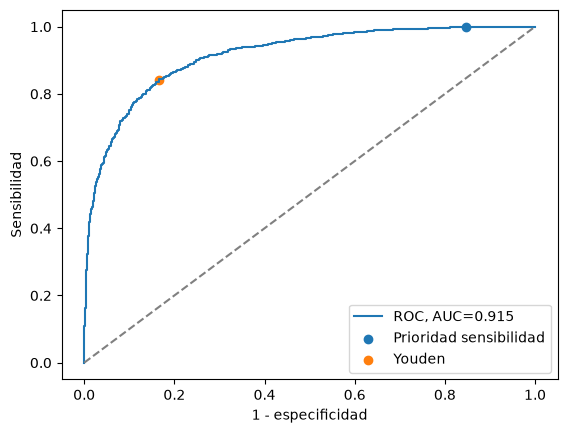

AUC teórica: 0.9213503964748574


In [3]:
# Recorremos umbrales e incluimos los extremos de la curva.
umbrales = np.r_[-np.inf, np.linspace(6, 18, 1000), np.inf]
tabla = pd.DataFrame([metricas_umbral(sanos, enfermos, b) for b in umbrales])
tabla['FPR'] = 1 - tabla.especificidad
tabla['Youden'] = tabla.sensibilidad + tabla.especificidad - 1

# El criterio del ejemplo docente prioriza sensibilidad máxima y luego especificidad.
prioridad_sensibilidad = tabla.sort_values(['sensibilidad', 'especificidad'], ascending=False).iloc[0]
# Youden da igual importancia a ambas tasas; es otro criterio, no el mismo óptimo.
youden = tabla.loc[tabla.Youden.idxmax()]
display(pd.DataFrame([prioridad_sensibilidad, youden], index=['Prioridad sensibilidad', 'Youden']))

y = np.r_[np.zeros(len(sanos)), np.ones(len(enfermos))]
scores = np.r_[sanos, enfermos]
fpr, tpr, _ = roc_curve(y, scores)
auc = roc_auc_score(y, scores)
plt.plot(fpr, tpr, label=f'ROC, AUC={auc:.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.scatter(prioridad_sensibilidad.FPR, prioridad_sensibilidad.sensibilidad,
            label='Prioridad sensibilidad')
plt.scatter(youden.FPR, youden.sensibilidad, label='Youden')
plt.xlabel('1 - especificidad')
plt.ylabel('Sensibilidad')
plt.legend()
plt.show()
print('AUC teórica:', norm.cdf((13 - 11) / np.sqrt(2)))

## 2. Acercar las distribuciones

Mantengo la dispersión y acerco las medias. Comparo AUC simulada y teórica: con distribuciones iguales, la teórica es 0.5. Los resultados corresponden a esta simulación.

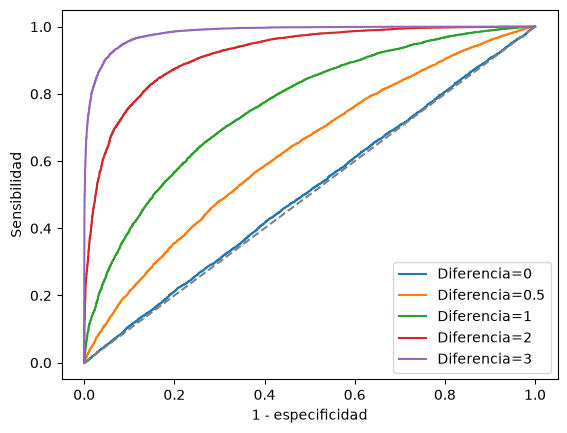

,diferencia de medias,AUC simulada,AUC teórica
0,0.0,0.508092,0.500000
1,0.5,0.628836,0.638163
2,1.0,0.763112,0.760250
3,2.0,0.919035,0.921350
4,3.0,0.982767,0.983053


In [4]:
filas = []
for separacion in [0., .5, 1., 2., 3.]:
    negativos = rng.normal(11, 1, 10000)
    positivos = rng.normal(11 + separacion, 1, 10000)
    etiquetas = np.r_[np.zeros(10000), np.ones(10000)]
    valores = np.r_[negativos, positivos]
    fpr, tpr, _ = roc_curve(etiquetas, valores)
    plt.plot(fpr, tpr, label=f'Diferencia={separacion:g}')
    filas.append({'diferencia de medias': separacion,
                  'AUC simulada': roc_auc_score(etiquetas, valores),
                  'AUC teórica': norm.cdf(separacion / np.sqrt(2))})
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('1 - especificidad')
plt.ylabel('Sensibilidad')
plt.legend()
plt.show()
display(pd.DataFrame(filas))